# Criando a primeira rede neural artificial: ` Perceptron `

O ` Perceptron ` é a forma mais simples de configuração para representar uma rede neural artificial e serve como base para redes mais complexas .

Proposto em 1958 pelo cientista Frank Rosenblatt , o modelo computacional foi inspirado na retina e uma de suas primeiras aplicações foi a identificação de padrões geométricos , imitando de forma simplificada um neurônio biológico .

### Arquitetura e Princípio de Funcionamento
O ` Perceptron ` é utilizado para problemas de classificação binária e é treinado para resolver problemas que são linearmente separáveis .

A imagem a seguir ilustra a arquitetura clássica de um ` Perceptron ` :

<div align="center">
    <img src="imagens/perceptron_illustration.png" width="500" height="250">
</div>

Observando a estrutura , podemos dividir seu funcionamento em três componentes principais :

- **Entradas ( ` X1 ` , ` X2 ` , ... , ` Xn ` ) :** Recebem os valores de dados que representam o problema a ser mapeado . Essas entradas serão nosso ` x ` .
- **Pesos ( ` W1 ` , ` W2 ` , ... , ` Wn ` )** : São valores numéricos que indicam a importância de cada entrada para chegar a uma decisão final e que são ajustados durante o processo de treinamento . Quanto maior o peso de uma entrada , maior é a importância daquele dado para chegar a uma decisão .
- **Viés ou Limiar ( ` θ ` = ` W0 ` )** : Esse é um valor constante que será somado a nossa soma ponderada , ajudando a acertar a linha de decisão . Na ilustração , ele é representado pela entrada fixa ` -1 ` ( ` X0 ` ) .

O processo ocorre em duas etapas matemáticas . Inicialmente , o neurônio calcula o Potencial de Ativação ( ` u ` ) , representado pelo símbolo de somatório ( ` Σ ` ) na imagem . Esse valor é a soma de todas as entradas multiplicada pelos seus respectivos Pesos e ajustada pelo Viés . Em seguida , o valor ` u ` é passado para a função de ativação ` g(x) ` , que transforma o resultado em uma decisão final , a saída ` y ` . As funções de ativação normalmente utilizadas no ` Perceptron ` são a função degrau ( 0 ou 1 ) ou a degrau bipolar ( -1 ou 1 ) .

### A Fronteira de Decisão e a Separabilidade Linear

O objetivo principal do ` Perceptron ` é decidir se uma determinada amostra pertence à classe ` +1 ` ou à classe ` -1 ` . Para isso , ele avalia o valor de ` u ` : se for positivo , a amostra é da classe ` +1 ` ; se for negativo , é da classe ` -1 ` .

Mas o que acontece se ` u ` for exatamente zero ? Esse é o ponto exato onde estamos na fronteira de decisão .

<div align="center">
    <img src="imagens/decision_boundary_illustration.png" width="500" height="500">
</div>

A imagem acima ilustra uma reta que é a fronteira de decisão para casos em que o ` Perceptron ` possui amostras de duas entradas ( ` x1 ` e ` x2 ` ) . A equação matemática que representa essa fronteira é ` w1*x1 + w2*x2 - θ = 0 ` , uma equação de primeiro grau que sempre descreverá uma reta .

Por essa razão o ` Perceptron ` é conhecido como um "classificador linear" , cuja função é classificar classes que são linearmente separáveis . Na Figura 2 , notamos claramente essa separação : as amostras da Classe A ( círculos azuis ) estão posicionadas abaixo da reta ( saída ` -1 ` ) , enquanto as da Classe B ( círculos laranjas ) estão acima da reta ( saída ` +1 ` ) .

### O Algoritmo de Aprendizado: Como o modelo aprende ?

Para que o ` Perceptron ` encontre essa reta perfeita , ele precisa ser treinado . O ajuste dos pesos e do limiar é realizado por meio da regra de aprendizado de ` Hebb ` . A regra prática é : "corrigir somente quando errar" . Se a saída do ` Perceptron ` condiz com a saída desejada , os pesos permanecem iguais ; caso contrário , eles são ajustados proporcionalmente ao erro .

Esse treinamento ocorre em ciclos chamados épocas . Uma época representa um ciclo completo de apresentação , no qual todas as amostras do conjunto de dados são mostradas à rede uma vez .

<div align="center">
    <img src="imagens/decision_boundary_epochs_illustration.png" width="500" height="500">
</div>

A Figura acima ilustra perfeitamente o processo de convergência ao longo de várias épocas . Note como a reta de decisão começa longe da solução ideal na primeira época , representada pela linha tracejada ( 1 ) . A cada época subsequente ( ( 2 ) , ( 3 ) , ... ) , a reta é ajustada com base nos erros que comete , movendo-se progressivamente pelo plano cartesiano . O treinamento para quando a convergência é atingida : o ponto em que a reta ( linha sólida ) consegue separar corretamente todos os pontos da Classe A e da Classe B .

### A Matemática do Aprendizado: Entendendo a Atualização de Pesos

Durante o treinamento , caso o modelo erre a previsão ( ou seja , se o valor previsto ` y ` for diferente do valor desejado ` d ` ) , precisamos recalcular o vetor de pesos ` w ` . A linha de código responsável por isso é a implementação exata da fórmula matemática utilizada para corrigir os pesos :

```python
w = w + learning_rate * (d - y) * x
```

Podemos entender essa equação dividindo-a em quatro partes fundamentais :

- ` w + ... ` : A base do cálculo é pegar os pesos antigos e somar uma correção a eles .
- ` (d - y) ` : Esta é a parte mais importante , o cálculo do erro . Note que se a rede acerta ( ` y == d ` ) , essa parte se torna zero e nenhuma correção é feita , exatamente como na regra de ` Hebb ` . Se a rede erra , o valor será ` -2 ` ou ` +2 ` , oferecendo o suporte e a orientação necessárias para o ajuste .
- ` * x ` : A correção é proporcional às entradas ` x ` que causaram o erro . Isso significa que os pesos conectados às entradas que mais influenciaram na decisão errada serão os mais alterados .
- ` learning_rate * ... ` : A taxa de aprendizado funciona como um "controle de volume" para o ajuste , definindo o quão rápido o treinamento do ` Perceptron ` irá convergir . A escolha de uma taxa de aprendizado deve ser realizada de forma cautelosa , evitando-se instabilidades no processo de treinamento . Usualmente , adota-se valores compreendidos no intervalo ` 0 < learning_rate < 1 ` .

### A Função de Previsão ( ` predict ` )

A função ` predict() ` recebe dois parâmetros , o vetor de pesos ` w ` e o vetor de entradas da amostra , calcula o somatório e esse resultado passa para a função de ativação , retornando ` -1 ` ou ` 1 ` , que é o nosso ` y ` .

```python
def predict(w, x):
    # 1. Calcula o Potencial de Ativação (u): soma ponderada das entradas e pesos
    u = np.dot(w, x)
    
    # 2. Passa o resultado pela função de ativação (degrau bipolar)
    if u >= 0:
        return 1
    else:
        return -1
```

### Implementação em ` Python `

Para traduzir essa teoria em código , utilizamos bibliotecas comuns no aprendizado de máquina , como ` numpy ` e ` pandas ` ( já citado anteriormente ) . Abaixo temos a função de treinamento que implementa a regra de ` Hebb ` , o controle de épocas e a verificação de convergência :

```python
import numpy as np
import pandas as pd

rng = np.random.default_rng(42) # Para manter os dados consistentes cria-se uma seed para conseguir obter os mesmos resultados.

def train(dataframe, learning_rate=0.01, max_epochs=1000):
    # 1. Inicializa os pesos com valores aleatorios
    w = rng.random(4)
    
    # 2. Inicia o loop principal das epocas
    for epoch in range(max_epochs):
        error_found_in_epoch = False
        
        # 3. Loop interno que passa por cada amostra
        for _, row in dataframe.iterrows():
            x1, x2, x3, d = row
            x = np.array([-1, x1, x2, x3])
            y = predict(w, x)
            
            # Se a previsao estiver errada, ajusta os pesos
            if y != d:
                w = w + learning_rate * (d - y) * x
                error_found_in_epoch = True
                
        # 4. Ao final da epoca, verifica se a convergencia foi atingida
        if not error_found_in_epoch:
            print(f"Treinamento concluido na epoca {epoch + 1}!")
            break
            
    else:
        print(f"O treinamento nao convergiu em {max_epochs} epocas.")
        
    return w
```

## Conclusão

O ` Perceptron ` , como já vimos , é um modelo fundamental para a inteligência artificial e para a classificação . Seu ponto forte em resolver problemas linearmente separáveis é também uma de suas limitações : a incapacidade de lidar com dados que não são linearmente separáveis . Essa barreira levou ao desenvolvimento de uma nova rede neural : Redes ` Perceptron ` Multicamadas , aptas a criar fronteiras de decisão complexas e resolver problemas que o ` Perceptron ` simples não é capaz de resolver .

---

## FAQ - Perguntas Frequentes

### 1. Como se processa a regra de ` Hebb ` no contexto do ` Perceptron `?

A regra de ` Hebb ` no ` Perceptron ` baseia-se no princípio de ajuste por erro . Durante o treinamento , se a saída prevista ( ` y ` ) for diferente da saída desejada ( ` d ` ) , os pesos ( ` w ` ) são atualizados proporcionalmente ao erro e à entrada ( ` x ` ) . Se o modelo acerta a previsão , nenhuma alteração é realizada , seguindo a diretriz de "corrigir somente quando houver erro" .

### 2. Como a taxa de aprendizado influencia a convergência?

A utilização de valores inapropriados para a taxa de aprendizado ( ` learning_rate ` ) pode causar instabilidade no processo de convergência . Uma taxa muito alta pode fazer com que a fronteira de decisão oscile drasticamente entre as épocas , impedindo o modelo de estabilizar em uma solução ideal . Já uma taxa muito baixa torna o treinamento excessivamente lento .

O código abaixo ilustra visualmente a diferença entre uma taxa instável e uma estável :

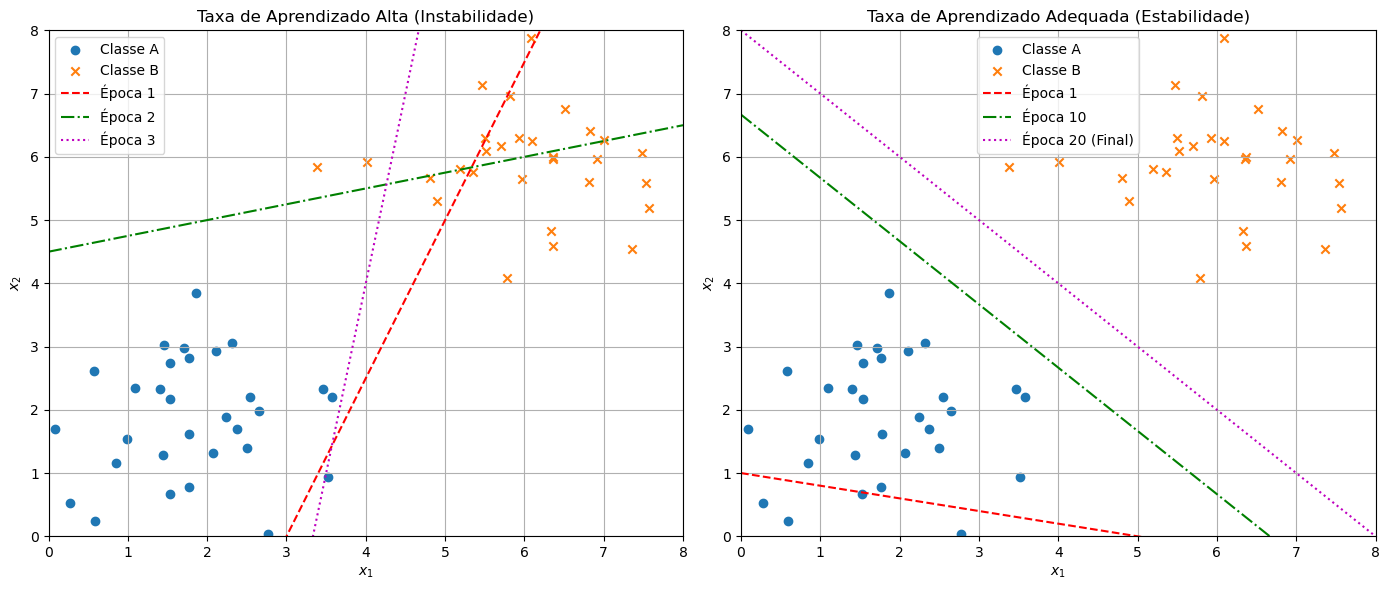

In [1]:
import matplotlib.pyplot as plt
import numpy as np

# Geração de dados sintéticos para duas classes
np.random.seed(42)
class_a_x1 = np.random.normal(2, 1, 30)
class_a_x2 = np.random.normal(2, 1, 30)
class_b_x1 = np.random.normal(6, 1, 30)
class_b_x2 = np.random.normal(6, 1, 30)

fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(14, 6))
x_vals = np.linspace(0, 8, 10)

# --- Plot 1: Taxa de Aprendizado Alta (Instabilidade) ---
ax1.scatter(class_a_x1, class_a_x2, marker='o', label='Classe A')
ax1.scatter(class_b_x1, class_b_x2, marker='x', label='Classe B')
# Simulação de retas oscilantes
ax1.plot(x_vals, (-0.5/-0.2) * x_vals + (1.5/-0.2), 'r--', label='Época 1')
ax1.plot(x_vals, (--0.1/0.4) * x_vals + (1.8/0.4), 'g-.', label='Época 2')
ax1.plot(x_vals, (-0.6/-0.1) * x_vals + (2.0/-0.1), 'm:', label='Época 3')

ax1.set_title('Taxa de Aprendizado Alta (Instabilidade)')
ax1.set_xlabel('$x_1$')
ax1.set_ylabel('$x_2$')
ax1.set_xlim(0, 8)
ax1.set_ylim(0, 8)
ax1.legend()
ax1.grid(True)

# --- Plot 2: Taxa de Aprendizado Adequada (Estabilidade) ---
ax2.scatter(class_a_x1, class_a_x2, marker='o', label='Classe A')
ax2.scatter(class_b_x1, class_b_x2, marker='x', label='Classe B')
# Simulação de retas convergentes
ax2.plot(x_vals, (-0.1/0.5) * x_vals + (0.5/0.5), 'r--', label='Época 1')
ax2.plot(x_vals, (-0.3/0.3) * x_vals + (2.0/0.3), 'g-.', label='Época 10')
ax2.plot(x_vals, (-0.5/0.5) * x_vals + (4.0/0.5), 'm:', label='Época 20 (Final)')

ax2.set_title('Taxa de Aprendizado Adequada (Estabilidade)')
ax2.set_xlabel('$x_1$')
ax2.set_ylabel('$x_2$')
ax2.set_xlim(0, 8)
ax2.set_ylim(0, 8)
ax2.legend()
ax2.grid(True)

plt.tight_layout()
plt.show()

### 3. Por que o ` Perceptron ` simples só classifica padrões linearmente separáveis?

A fronteira de decisão do ` Perceptron ` é definida matematicamente por uma equação linear do tipo ` w1*x1 + w2*x2 + ... + wn*xn - θ = 0 `. Esta expressão descreve geometricamente uma reta ( em 2D ), um plano ( em 3D ) ou um hiperplano ( em dimensões superiores ). Devido à natureza linear desta fronteira, o modelo é incapaz de separar classes que exijam uma demarcação curva ou não linear.

### 4. Qual a importância de tratar o limiar de ativação ( ` θ ` ) como um peso ( ` w ` )?

Integrar o limiar de ativação ( ` θ ` ) ao vetor de pesos ( ` w ` ) simplifica a implementação algorítmica. Ao tratar o limiar como um peso adicional ( ` w0 ` ) associado a uma entrada fixa ( geralmente ` -1 ` ou ` +1 ` ), o cálculo do potencial de ativação torna-se um produto escalar puro entre dois vetores. Isso permite utilizar operações matriciais otimizadas e unifica o processo de atualização de todos os parâmetros do modelo.

### 5. Como verificar se um problema é separável linearmente?

Uma abordagem prática consiste em submeter o conjunto de dados ao treinamento do ` Perceptron ` com um limite máximo de épocas ( ` max_epochs ` ) definido. Caso o algoritmo atinja a convergência ( erro zero em uma época completa ) dentro desse limite, confirma-se que as classes são linearmente separáveis. Se a convergência não ocorrer e o erro oscilar ou permanecer alto, é um forte indicativo de que o problema exige um modelo não linear, como uma Rede Neural Multicamadas ( ` MLP ` ).

### 6. Duas redes treinadas para o mesmo problema terão sempre o mesmo desempenho?

Não necessariamente. Mesmo que duas redes convirjam para o mesmo problema, elas podem chegar a fronteiras de decisão diferentes. Para um problema linearmente separável, existem infinitas retas que podem separar as classes. A solução final depende da inicialização aleatória dos pesos e da taxa de aprendizado. Consequentemente, amostras novas localizadas muito próximas à fronteira de decisão podem ser classificadas de forma diferente por cada uma das redes.

### 7. O ` Perceptron ` pode resolver o problema do ` XOR `?

Não. No problema do ` XOR `, as amostras das classes estão distribuídas de forma que é impossível traçar uma única linha reta que as separe. Como o ` Perceptron ` simples é um classificador linear, ele não consegue convergir para uma solução neste cenário, o que motivou historicamente o desenvolvimento de redes com camadas ocultas.